In [184]:
import numpy as np
import tensorflow as tf
import pandas as pd
import tensorflow_probability as tfp
import random

from skimage.morphology import skeletonize, thin

from sklearn.model_selection import train_test_split


In [2]:
root = """data\\"""
img_size = (128, 128)

In [142]:
src = pd.read_csv("data\english.csv")
# src.head()

,image,label
0,Img/img001-001.png,0
1,Img/img001-002.png,0
2,Img/img001-003.png,0
3,Img/img001-004.png,0
4,Img/img001-005.png,0


In [148]:
def load_img(name):
    loc = root + name.rstrip()
    img = tf.keras.preprocessing.image.load_img(loc, target_size=img_size, color_mode="grayscale")
    img = tf.convert_to_tensor(img, dtype=tf.float32) / 255.0
    img = 1 - img
    return img

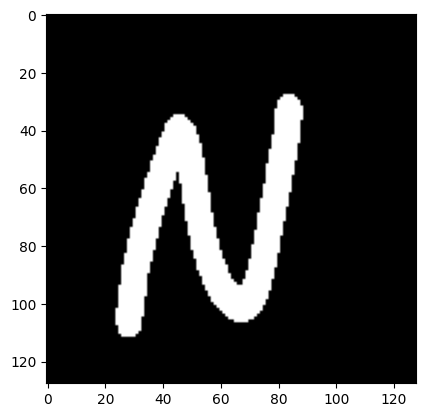

In [166]:
import matplotlib.pyplot as plt

img = load_img("Img/img024-001.png	")
plt.imshow(img, cmap='gray', vmin=0, vmax=1)

Make the image blurry

In [150]:
def randomise(image: tf.Tensor):
    random_values = tf.random.uniform(shape=(8,8,1), minval=0.1, maxval=0.9)
    random_values = tf.reshape(tf.image.resize(random_values, img_size, method="bilinear"), img_size)
    mask = tf.math.greater(image, 0.8)
    return tf.where(mask, random_values, image)

In [151]:
def skeleton(blur):
    sk = thin(blur.numpy(), 1)

    skeletons = [blur, tf.constant(sk, dtype=tf.float32)]

    for j in range(4):
        sk = thin(sk, 1)
        skeletons.append(tf.constant(sk, dtype=tf.float32))

    # Average it out; enh = enhanced
    enh = tf.add_n(skeletons) / len(skeletons)
    return enh

In [152]:
def gaussian_kernel(size: int, mean: float, std: float):
    """Generates a Gaussian kernel to be used for blurring"""
    d = tfp.distributions.Normal(mean, std)
    vals = d.prob(tf.range(start=-size, limit=size+1, dtype=tf.float32))
    gauss_kernel = tf.einsum('i,j->ij', vals, vals)
    gauss_kernel = gauss_kernel / tf.reduce_sum(gauss_kernel)  # Normalize the kernel
    return gauss_kernel[:, :, tf.newaxis, tf.newaxis]

def apply_gaussian_blur(image: tf.Tensor, kernel_size: int, sigma: float):
    kernel = gaussian_kernel(kernel_size, 0., sigma)
    kernel = tf.tile(kernel, [1, 1, image.shape[-1], 1])  # Adjust the kernel to work for each image channel
    image = tf.expand_dims(image, axis=0)  # Add a batch dimension for convolution
    blurred_image = tf.nn.depthwise_conv2d(image, kernel, strides=[1, 1, 1, 1], padding='SAME')
    return tf.squeeze(blurred_image, axis=0)  # Remove the batch dimension

def blur(img):
    blur = tf.reshape(img, [128, 128, 1])
    blur = apply_gaussian_blur(blur, 3, 1.5)
    return tf.reshape(blur, img_size)

In [164]:
def noise(image: tf.Tensor, num_groups: int = 10):
    # Detect black regions (0 value pixels)
    black_pixels = tf.where(image == 0)

    # Randomly select positions to add white pixel groups
    for _ in range(num_groups):
        if len(black_pixels) == 0:
            break  # If no more black pixels are available, stop
        
        # Randomly choose a black pixel location
        random_idx = random.randint(0, len(black_pixels) - 1)
        x, y = black_pixels[random_idx]

        x_d = random.randint(2,4)
        y_d = random.randint(2,4)

        # Define the area to replace with white pixels (within bounds)
        x_start = max(0, x - x_d // 2)
        y_start = max(0, y - y_d // 2)
        x_end = min(image.shape[0], x_start + x_d)
        y_end = min(image.shape[1], y_start + y_d)

        x_d = x_end - x_start
        y_d = y_end - y_start

        # Add white pixels to the selected region
        image = tf.tensor_scatter_nd_update(
            image, 
            indices=tf.convert_to_tensor([[i, j] for i in range(x_start, x_end) for j in range(y_start, y_end)]),
            updates=tf.random.uniform([(x_d * y_d)], minval=0.1, maxval=1.0, dtype=tf.float32)
        )
    
    return image

In [175]:
final = tf.reshape(noise(skeleton(randomise(blur(img)))), [img_size[0], img_size[1],1])

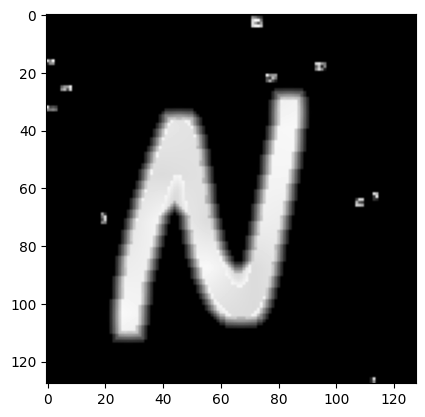

In [176]:
plt.imshow(final, cmap='gray', vmin=0, vmax=1)

------------

Image multiplication

In [141]:
# This will be worked on later; it has already be achieved with the existing module provided by Keras

---------

In [ ]:
imgs = []
labels = []

for i in range(len(src)):
    x = load_img(src.iloc[i]['image'])
    x = tf.reshape(noise(skeleton(randomise(blur(x)))), [1,img_size[0], img_size[1],1])
    imgs.append(x)

    y = src.iloc[i]['label']
    labels.append(y)

    # plt.imshow(x, cmap='gray', vmin=0, vmax=1)

    # print(y)

In [217]:
x_train, x_test, y_train, y_test = train_test_split(imgs, labels, test_size=0.1, random_state=2)

In [231]:
x_train = tf.concat(x_train, 0)
x_test = tf.concat(x_test, 0)
y_train = tf.constant(y_train, dtype=tf.string)
y_test = tf.constant(y_test, dtype=tf.string)

In [279]:
datagen = tf.keras.preprocessing.image.ImageDataGenerator(
    rotation_range=10,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.1
)

datagen.fit(x_train)
train_ds = datagen.flow(x_train, y_train, batch_size=512)

In [302]:
# The below is how you are to apply the data augumentation method:

# Train the model with data augmentation
history = model.fit(
    datagen.flow(X_train, y_train, batch_size=32),
    epochs=50,
    validation_data=(X_val, y_val),
    callbacks=[early_stopping, model_checkpoint, reduce_lr]
)